# 08c - Will congestion start here in the next 30 minutes?

**Question:** at a sensor on I-5 northbound, will congestion **start** in the next 5-30 minutes?

- **Congestion:** speed below 40 mph in at least 4 of 6 readings (30 minutes).
- **Asked at every moment** (weekdays, 6:00-19:55), whether the road is fast, slowing or already congested.
  A congestion episode that is already under way is not a new start.

**Features (27):** flow, speed and density at the sensor and at its adjacent upstream and downstream
sensors, now and as changes over the last 5 and 10 minutes.

**Models:** 11 classifiers, each with and without class balancing, and a flow-only baseline. Evaluated on 4
time-ordered validation windows, with random 5-fold cross-validation as a comparison.

**Built on `data_and_features.ipynb`.** That notebook is run first (without its models). From it we use:
- `main`: real mainline readings (`pct_observed` = 100), weekdays, 5:00-20:55, duplicates removed
- `station_order`: each sensor's **adjacent** upstream and downstream sensor
- the prediction window (`DAY_START`-`DAY_END`, 6:00-19:55)
- the 4 expanding validation windows (`val_windows`) and the Jul-Dec 2025 holdout, which stays
  locked unless `RUN_FINAL_TEST` is switched on

## 1. Settings

In [1]:
HORIZON = 6                  # readings ahead: 6 = congestion starting in the next 5-30 minutes
CONGESTED_MPH = 40           # a reading is slow if speed is below 40 mph
WINDOW = 6                   # look at 6 readings (30 minutes) ...
MIN_SLOW = 4                 # ... congested if at least 4 of them are slow
TRAIN_SAMPLE = 100_000       # training rows per fold (random sample)
VAL_SAMPLE = 200_000         # validation rows per fold (random sample)
CV_SAMPLE = 50_000           # rows for the random cross-validation (section 8)
RESULTS = "../../results/"
SUFFIX = f"_40mph_h{HORIZON}"  # added to saved file names (does not overwrite 08 / 08b results)

## 2. Load the data from `data_and_features.ipynb`

`SKIP_MODELS = True` tells that notebook to skip its model cells; `%run -i` makes its tables
available here. This takes about 2 minutes.

In [2]:
SKIP_MODELS = True
%run -i data_and_features.ipynb

1094 daily files found


Loaded 100/1094 files


Loaded 150/1094 files


Loaded 200/1094 files


Loaded 250/1094 files


...

rows before: 3877419


rows after:  3501571


first and last prediction times: 06:00:00 19:55:00


fold 1: 530,700 training rows, 382,456 validation rows
fold 2: 913,156 training rows, 666,339 validation rows
fold 3: 1,579,495 training rows, 595,133 validation rows
fold 4: 2,174,628 training rows, 637,682 validation rows
test: 689,261 rows


Model cells skipped (SKIP_MODELS = True).
Final test not run yet (set RUN_FINAL_TEST = True when all choices are made).


In [3]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from lightgbm import LGBMClassifier
try:
    from imblearn.ensemble import BalancedRandomForestClassifier   # pip install imbalanced-learn
except ImportError:
    BalancedRandomForestClassifier = None
    print("imbalanced-learn not installed: the balanced random forest is skipped "
          "(pip install imbalanced-learn)")
from sklearn.svm import LinearSVC, SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve, roc_curve
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)
os.makedirs(RESULTS, exist_ok=True)
print("real mainline readings:", len(main))
print("validation windows:", val_windows, "| holdout:", test_start.date(), "to", test_end.date())

real mainline readings: 4006634
validation windows: [('2023-07-01', '2024-01-01'), ('2024-01-01', '2024-07-01'), ('2024-07-01', '2025-01-01'), ('2025-01-01', '2025-07-01')] | holdout: 2025-07-01 to 2026-01-01


## 3. Wide tables: one row per 5-minute slot, one column per sensor

Sensors are in road order (`station_order`). A missing (estimated) reading is an empty cell.
Density is not in PeMS, so it is computed as **flow / speed** (vehicles per hour / mph = vehicles
per mile).

In [4]:
ids = station_order["ID"].tolist()
up_of = dict(zip(station_order["ID"], station_order["upstream_id"]))
down_of = dict(zip(station_order["ID"], station_order["downstream_id"]))

all_times = pd.date_range(main["timestamp"].min().normalize(),
                          main["timestamp"].max().normalize() + pd.Timedelta("23:55:00"), freq="5min")
speed = main.pivot(index="timestamp", columns="station", values="speed").reindex(index=all_times, columns=ids)
flow = main.pivot(index="timestamp", columns="station", values="flow").reindex(index=all_times, columns=ids) * 12
density = flow / speed.where(speed > 0)
print(speed.shape)

(315360, 44)


## 4. Congestion and the label

**Slow reading:** speed below 40 mph (`CONGESTED_MPH`, the same at every sensor).

**Congested at time s:** at least 4 of the 6 readings from s to s+25 minutes are slow (`MIN_SLOW` of
`WINDOW`). A single fast reading inside a jam doesn't end it, and a single slow reading isn't a jam.

**Congestion starts at s** if the window starting at s is congested and the window starting at s-5 min
is not. Because the window looks 30 minutes ahead, the start can be up to 10 minutes before the first
reading below 40 mph (at most 2 of the 6 readings can be fast).

**Label:** the row at time t gets label 1 if congestion starts in the next `HORIZON` readings
(5-30 minutes). The label only counts if every reading it depends on, from t to
t + (`HORIZON` + `WINDOW` - 1) x 5 minutes, is real.

In [5]:
threshold = pd.Series(float(CONGESTED_MPH), index=ids)   # same for every sensor (used by Kaplan-Meier)

slow = (speed < CONGESTED_MPH).astype(int)

# number of slow readings in the 6 readings from t to t+25 min:
# rolling(6) counts t-25..t, shift(-5) moves that count back to t
slow_count = slow.rolling(WINDOW).sum().shift(-(WINDOW - 1))
congested = slow_count >= MIN_SLOW

starts = congested & ~congested.shift(1, fill_value=False)

label = pd.DataFrame(False, index=all_times, columns=ids)
for h in range(1, HORIZON + 1):
    label = label | starts.shift(-h, fill_value=False)

# a label at t needs real readings from t to t + (HORIZON + WINDOW - 1) steps
known = speed.notna()
for k in range(1, HORIZON + WINDOW):
    known = known & speed.shift(-k).notna()

name_of = dict(zip(meta_d12["ID"], meta_d12["Name"]))
print(f"congestion starts: {int(starts.sum().sum()):,}")
print(f"share of checkable rows labelled 1: {label[known].sum().sum() / known.sum().sum():.2%}")
per_sensor = starts.sum().reindex(ids)
print("most congestion starts:",
      {name_of.get(s, s): int(n) for s, n in per_sensor.sort_values(ascending=False).head(5).items()})

congestion starts: 15,508


share of checkable rows labelled 1: 2.44%
most congestion starts: {'RED HILL': 1435, 'ANAHEIM 2': 1223, 'CONCORD': 1172, 'S OF HARBOR': 1106, '17TH 2': 1065}


## 5. The 27 features

For the sensor (`i`), its adjacent upstream sensor (`up`) and its adjacent downstream sensor (`down`):
- flow `q`, speed `u`, density `k` now (9 features)
- their change over the last 5 minutes, e.g. `du1_up` = u(t) - u(t-5 min) upstream (9 features)
- their change over the last 10 minutes, e.g. `du2_i` = u(t) - u(t-10 min) (9 features)

A row is used only if all 27 values are real. When the adjacent sensor's reading was estimated, the row
is dropped.

In [6]:
hours = all_times.hour
in_window = (hours >= DAY_START) & (hours < DAY_END)            # 6:00-19:55, from data_and_features

parts = []
for sid in ids:
    df = pd.DataFrame(index=all_times)
    for where, nid in [("i", sid), ("up", up_of[sid]), ("down", down_of[sid])]:
        for name, table in [("q", flow), ("u", speed), ("k", density)]:
            if pd.isna(nid):                                     # first/last sensor has no neighbor
                df[f"{name}_{where}"] = np.nan
                df[f"d{name}1_{where}"] = np.nan
                df[f"d{name}2_{where}"] = np.nan
                continue
            values = table[nid]
            df[f"{name}_{where}"] = values
            df[f"d{name}1_{where}"] = values - values.shift(1)
            df[f"d{name}2_{where}"] = values - values.shift(2)
    df["label"] = label[sid].astype(int)
    df["station"] = sid
    keep = in_window & known[sid].to_numpy()
    df = df[keep].dropna()
    parts.append(df.rename_axis("timestamp").reset_index())

data = pd.concat(parts, ignore_index=True)
del parts
ALL_27 = [c for c in data.columns if c not in ["timestamp", "station", "label"]]
# a smaller set: all 9 current levels + 4 change features (used in section 10)
CORE_13 = ["u_i", "du2_i", "u_up", "k_up", "u_down", "q_up", "q_i", "k_i", "k_down", "q_down",
            "du2_down", "dk1_down", "du1_up"]

# the label depends on readings up to this time; folds are split on it so no label crosses a boundary
data["label_time"] = data["timestamp"] + pd.Timedelta(minutes=5 * (HORIZON + WINDOW - 1))
print(f"{len(data):,} rows with all 27 features real | congestion-start share {data['label'].mean():.2%}")
print("rows per year:", data["timestamp"].dt.year.value_counts().sort_index().to_dict())

1,394,337 rows with all 27 features real | congestion-start share 2.65%
rows per year: {2023: 402883, 2024: 501886, 2025: 489568}


## 6. The models

**Class balancing** = weight the rows so both classes count equally in training.

| Model | Here |
|---|---|
| Logistic regression | `LogisticRegression(C=1e8)` (almost no regularization) |
| Naive Bayes | `GaussianNB` |
| Decision tree | `DecisionTreeClassifier(min_samples_leaf=20)` |
| Random tree | `DecisionTreeClassifier(max_features="log2")` |
| Random forest | `RandomForestClassifier(n_estimators=100)` |
| Linear SVM | `LinearSVC` + sigmoid calibration |
| Polynomial SVM | `SVC(kernel="poly", degree=2)`, 10,000 training rows (it is very slow) |
| Gradient boosting | `HistGradientBoostingClassifier`, 300 trees |
| LightGBM | `LGBMClassifier`, 300 trees |
| Balanced random forest | `BalancedRandomForestClassifier` (imbalanced-learn), 100 trees: each tree sees a 50/50 mix of congestion and normal rows, so it balances itself and runs only with class balancing = no |
| Extra trees | `ExtraTreesClassifier`, 100 trees: a faster, more random version of the random forest |

In [7]:
def make_model(name):
    if name == "Logistic regression":
        return Pipeline([("scale", StandardScaler()), ("model", LogisticRegression(C=1e8, max_iter=2000))])
    if name == "Naive Bayes":
        return Pipeline([("model", GaussianNB())])
    if name == "Decision tree":
        return Pipeline([("model", DecisionTreeClassifier(min_samples_leaf=20, random_state=0))])
    if name == "Random tree":
        return Pipeline([("model", DecisionTreeClassifier(max_features="log2", random_state=0))])
    if name == "Random forest":
        return Pipeline([("model", RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=0))])
    if name == "SVM-1 (linear)":
        return Pipeline([("scale", StandardScaler()),
                         ("model", CalibratedClassifierCV(LinearSVC(), method="sigmoid", cv=3))])
    if name == "SVM-2 (polynomial)":
        return Pipeline([("scale", StandardScaler()), ("model", SVC(kernel="poly", degree=2))])
    if name == "Gradient boosting":
        return Pipeline([("model", HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                                                  random_state=0))])
    if name == "LightGBM":
        return Pipeline([("model", LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                                                  verbose=-1, random_state=0))])
    if name == "Balanced random forest":
        return Pipeline([("model", BalancedRandomForestClassifier(n_estimators=100, sampling_strategy="all",
                                                                  replacement=True, bootstrap=False,
                                                                  n_jobs=-1, random_state=0))])
    if name == "Extra trees":
        return Pipeline([("model", ExtraTreesClassifier(n_estimators=100, min_samples_leaf=5,
                                                        n_jobs=-1, random_state=0))])


MODELS = ["Logistic regression", "Naive Bayes", "Decision tree", "Random tree", "Random forest",
          "SVM-1 (linear)", "SVM-2 (polynomial)",
          "Gradient boosting", "LightGBM", "Balanced random forest", "Extra trees"]
if BalancedRandomForestClassifier is None:
    MODELS.remove("Balanced random forest")

# which class-balancing settings to run for each model
# (the balanced random forest balances itself, so weighting it as well would balance it twice)
BALANCING = {name: [False, True] for name in MODELS}
if "Balanced random forest" in BALANCING:
    BALANCING["Balanced random forest"] = [False]


def balance_weights(y):
    return np.where(y == 1, (y == 0).sum() / (y == 1).sum(), 1.0)


def fit_and_predict(name, balanced, X_train, y_train, X_test, features):
    if name == "SVM-2 (polynomial)" and len(X_train) > 10_000:
        pick = np.random.default_rng(0).choice(len(X_train), 10_000, replace=False)
        X_train, y_train = X_train.iloc[pick], y_train[pick]
    model = make_model(name)
    if balanced:
        model.fit(X_train[features], y_train, model__sample_weight=balance_weights(y_train))
    else:
        model.fit(X_train[features], y_train)
    pred = model.predict(X_test[features])
    if hasattr(model, "predict_proba"):
        score = model.predict_proba(X_test[features])[:, 1]
    else:
        score = model.decision_function(X_test[features])
    return pred, score


def measures(y, pred, score=None):
    tp = ((pred == 1) & (y == 1)).sum()
    tn = ((pred == 0) & (y == 0)).sum()
    fp = ((pred == 1) & (y == 0)).sum()
    fn = ((pred == 0) & (y == 1)).sum()
    tpr = tp / max(tp + fn, 1)
    tnr = tn / max(tn + fp, 1)
    out = {"balanced accuracy": (tpr + tnr) / 2, "TPR (recall)": tpr, "TNR": tnr,
           "PPV (precision)": tp / max(tp + fp, 1), "NPV": tn / max(tn + fn, 1)}
    if score is not None:
        out["PR-AUC"] = average_precision_score(y, score)
        out["ROC-AUC"] = roc_auc_score(y, score)
    return out

## 7. Cross-validation over the 4 validation windows

Same windows as `data_and_features.ipynb`: train on everything before the window, test on the window.
Each fold uses a random sample of training and validation rows.

In [8]:
def fold_rows(val_start, val_end):
    train = data[(data["timestamp"] >= "2023-01-01") & (data["label_time"] < val_start)]
    val = data[(data["timestamp"] >= val_start) & (data["label_time"] < val_end)]
    train = train.sample(min(TRAIN_SAMPLE, len(train)), random_state=0).reset_index(drop=True)
    val = val.sample(min(VAL_SAMPLE, len(val)), random_state=0).reset_index(drop=True)
    return train, val


rows = []
for fold_number, (val_start, val_end) in enumerate(val_windows, start=1):
    train, val = fold_rows(val_start, val_end)
    for name in MODELS:
        for balanced in BALANCING[name]:
            pred, score = fit_and_predict(name, balanced, train, train["label"].to_numpy(), val, ALL_27)
            r = measures(val["label"].to_numpy(), pred, score)
            r.update({"fold": fold_number, "model": name, "class balancing": "yes" if balanced else "no"})
            rows.append(r)
    print(f"fold {fold_number} ({val_start} to {val_end}): {len(train):,} training rows, "
          f"{len(val):,} validation rows, congestion-start share {val['label'].mean():.2%}")

per_fold = pd.DataFrame(rows)
per_fold.to_csv(RESULTS + f"congestion_folds{SUFFIX}.csv", index=False)
summary = per_fold.groupby(["class balancing", "model"]).mean(numeric_only=True).drop(columns="fold")
summary.to_csv(RESULTS + f"congestion_fold_average{SUFFIX}.csv")
print("Average over the 4 folds")
summary.round(3)

fold 1 (2023-07-01 to 2024-01-01): 100,000 training rows, 134,089 validation rows, congestion-start share 2.78%


fold 2 (2024-01-01 to 2024-07-01): 100,000 training rows, 200,000 validation rows, congestion-start share 2.71%


fold 3 (2024-07-01 to 2025-01-01): 100,000 training rows, 198,106 validation rows, congestion-start share 2.87%


fold 4 (2025-01-01 to 2025-07-01): 100,000 training rows, 200,000 validation rows, congestion-start share 2.67%
Average over the 4 folds


balanced accuracy  TPR (recall)  \
class balancing model                                                     
no              Balanced random forest              0.830         0.806   
                Decision tree                       0.537         0.080   
                Extra trees                         0.500         0.000   
                Gradient boosting                   0.513         0.026   
                LightGBM                            0.519         0.038   
                Logistic regression                 0.501         0.007   
                Naive Bayes                         0.705         0.597   
                Random forest                       0.506         0.013   
                Random tree                         0.578         0.185   
                SVM-1 (linear)                      0.501         0.006   
                SVM-2 (polynomial)                  0.500         0.000   
yes             Decision tree                       0.737         0.587   
                Extra trees                         0.695         0.425   
                Gradient boosting                   0.842         0.857   
                LightGBM                            0.807         0.727   
                Logistic regression                 0.790         0.832   
                Naive Bayes                         0.743         0.724   
                Random forest                       0.553         0.112   
                Random tree                         0.562         0.143   
                SVM-1 (linear)                      0.790         0.832   
                SVM-2 (polynomial)                  0.706         0.575   

                                          TNR  PPV (precision)    NPV  PR-AUC  \
class balancing model                                                           
no              Balanced random forest  0.854            0.136  0.994   0.208   
                Decision tree           0.994            0.266  0.974   0.131   
                Extra trees             1.000            0.375  0.972   0.252   
                Gradient boosting       0.999            0.526  0.973   0.240   
                LightGBM                0.999            0.482  0.973   0.238   
                Logistic regression     0.995            0.010  0.972   0.085   
                Naive Bayes             0.814            0.084  0.986   0.081   
                Random forest           1.000            0.543  0.973   0.220   
                Random tree             0.970            0.153  0.977   0.051   
                SVM-1 (linear)          0.996            0.011  0.972   0.087   
                SVM-2 (polynomial)      1.000            0.000  0.972   0.067   
yes             Decision tree           0.888            0.130  0.987   0.130   
                Extra trees             0.966            0.259  0.983   0.248   
                Gradient boosting       0.828            0.124  0.995   0.221   
                LightGBM                0.886            0.154  0.991   0.232   
                Logistic regression     0.748            0.086  0.994   0.084   
                Naive Bayes             0.762            0.080  0.990   0.081   
                Random forest           0.995            0.379  0.975   0.229   
                Random tree             0.982            0.179  0.976   0.050   
                SVM-1 (linear)          0.747            0.086  0.994   0.084   
                SVM-2 (polynomial)      0.837            0.093  0.986   0.086   

                                        ROC-AUC  
class balancing model                            
no              Balanced random forest    0.910  
                Decision tree             0.748  
                Extra trees               0.913  
                Gradient boosting         0.911  
                LightGBM                  0.911  
                Logistic regression       0.840  
                Naive Bayes               0.821  


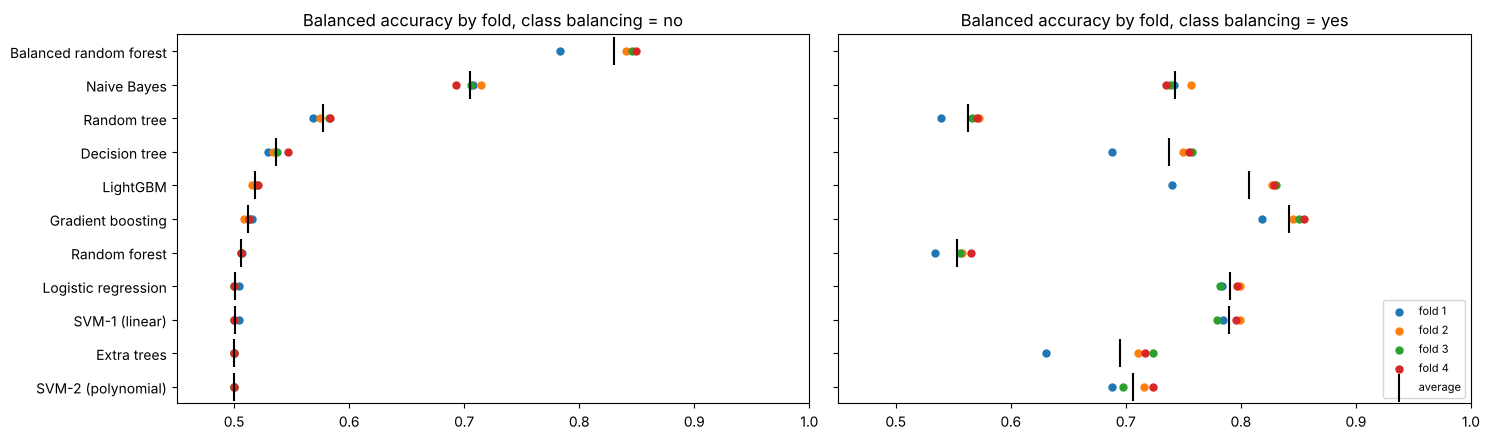

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, balancing in zip(axes, ["no", "yes"]):
    part = per_fold[per_fold["class balancing"] == balancing]
    table = part.pivot(index="model", columns="fold", values="balanced accuracy")
    table = table.loc[table.mean(axis=1).sort_values().index]
    for fold in table.columns:
        ax.scatter(table[fold], table.index, s=25, label=f"fold {fold}")
    ax.scatter(table.mean(axis=1), table.index, marker="|", s=400, color="black", label="average")
    ax.set_title(f"Balanced accuracy by fold, class balancing = {balancing}")
    ax.set_xlim(0.45, 1.0)
axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

### Precision-recall and ROC curves for every model (fold 4)

Each model is trained on the fold-4 training rows and scored on the fold-4 validation rows (Jan-Jun 2025),
the same rows as above, so the areas match the fold-4 results.

- **Precision-recall:** precision (share of warnings that were right) against recall (share of
  congestion starts warned about). Random guessing is a flat line at the share of label-1 rows.
- **ROC:** recall against the false positive rate (share of calm moments with a warning). Random
  guessing is the diagonal (0.5). With rare events, ROC-AUC looks much better than PR-AUC, so read the
  two together.

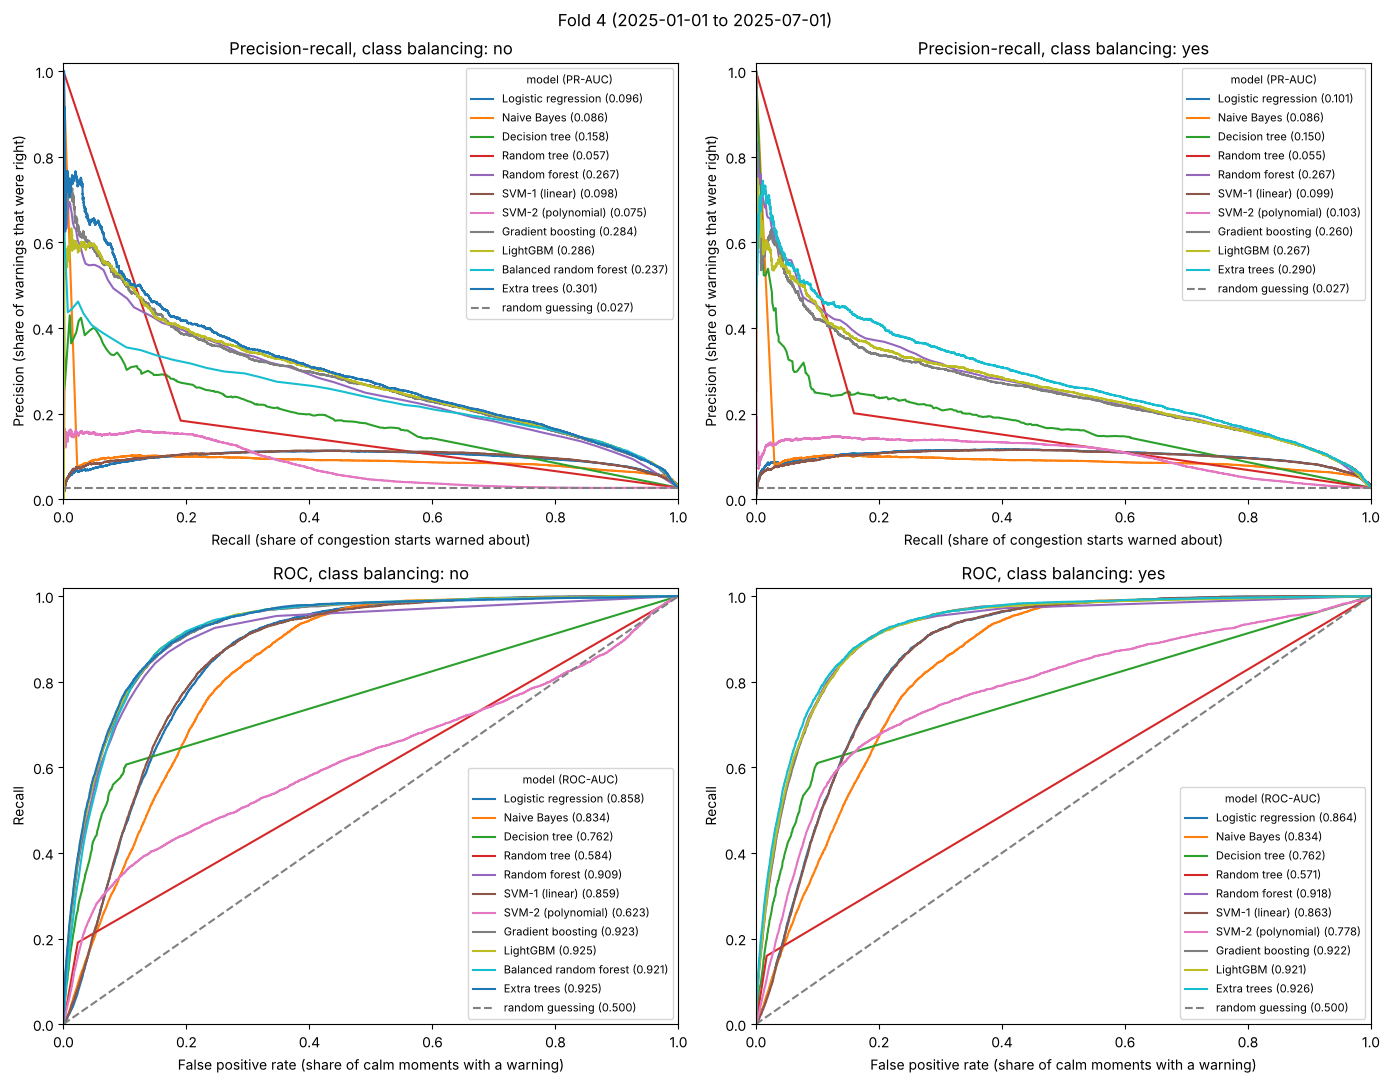

PR-AUC        ROC-AUC       
class balancing            no    yes      no    yes
model                                              
Balanced random forest  0.237    NaN   0.921    NaN
Decision tree           0.158  0.150   0.762  0.762
Extra trees             0.301  0.290   0.925  0.926
Gradient boosting       0.284  0.260   0.923  0.922
LightGBM                0.286  0.267   0.925  0.921
Logistic regression     0.096  0.101   0.858  0.864
Naive Bayes             0.086  0.086   0.834  0.834
Random forest           0.267  0.267   0.909  0.918
Random tree             0.057  0.055   0.584  0.571
SVM-1 (linear)          0.098  0.099   0.859  0.863
SVM-2 (polynomial)      0.075  0.103   0.623  0.778

In [10]:
FOLD = 4
train, val = fold_rows(*val_windows[FOLD - 1])
y_train = train["label"].to_numpy()
y_val = val["label"].to_numpy()

curve_scores = {}                                            # (model, balanced) -> scores on fold 4
for balanced in [False, True]:
    for name in MODELS:
        if balanced not in BALANCING[name]:
            continue
        _, curve_scores[(name, balanced)] = fit_and_predict(name, balanced, train, y_train, val, ALL_27)

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
areas = []
for col, balanced in enumerate([False, True]):
    ax_pr, ax_roc = axes[0, col], axes[1, col]
    for name in MODELS:
        if (name, balanced) not in curve_scores:
            continue
        score = curve_scores[(name, balanced)]
        precision, recall, _ = precision_recall_curve(y_val, score)
        fpr, tpr, _ = roc_curve(y_val, score)
        pr_auc, roc_auc = average_precision_score(y_val, score), roc_auc_score(y_val, score)
        ax_pr.plot(recall, precision, label=f"{name} ({pr_auc:.3f})")
        ax_roc.plot(fpr, tpr, label=f"{name} ({roc_auc:.3f})")
        areas.append({"model": name, "class balancing": "yes" if balanced else "no",
                      "PR-AUC": pr_auc, "ROC-AUC": roc_auc})
    ax_pr.axhline(y_val.mean(), color="grey", linestyle="--", label=f"random guessing ({y_val.mean():.3f})")
    ax_roc.plot([0, 1], [0, 1], color="grey", linestyle="--", label="random guessing (0.500)")
    balancing = "yes" if balanced else "no"
    ax_pr.set_title(f"Precision-recall, class balancing: {balancing}")
    ax_pr.set_xlabel("Recall (share of congestion starts warned about)")
    ax_pr.set_ylabel("Precision (share of warnings that were right)")
    ax_pr.legend(fontsize=8, title="model (PR-AUC)", title_fontsize=8)
    ax_roc.set_title(f"ROC, class balancing: {balancing}")
    ax_roc.set_xlabel("False positive rate (share of calm moments with a warning)")
    ax_roc.set_ylabel("Recall")
    ax_roc.legend(fontsize=8, title="model (ROC-AUC)", title_fontsize=8, loc="lower right")
    for ax in (ax_pr, ax_roc):
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1.02)
fig.suptitle(f"Fold {FOLD} ({val_windows[FOLD - 1][0]} to {val_windows[FOLD - 1][1]})")
plt.tight_layout()
plt.show()

pd.DataFrame(areas).pivot_table(index="model", columns="class balancing", values=["PR-AUC", "ROC-AUC"]).round(3)

## 8. For comparison: random 5-fold cross-validation

Random cross-validation shuffles all rows into 5 folds, ignoring time. Here it is run on a random sample
of the fold-4 training rows (Jan 2023-Dec 2024) and compared with fold 4 of the time-ordered evaluation
above. If random folds leak information between neighboring 5-minute rows, they will look better.

In [11]:
train4, _ = fold_rows(*val_windows[3])
cv_rows = train4.sample(min(CV_SAMPLE, len(train4)), random_state=1).reset_index(drop=True)
cv_folds = KFold(n_splits=5, shuffle=True, random_state=0)
rows_cv = []
for name in MODELS:
    for balanced in BALANCING[name]:
        y_true, y_pred = [], []
        for tr_idx, te_idx in cv_folds.split(cv_rows):
            tr, te = cv_rows.iloc[tr_idx], cv_rows.iloc[te_idx]
            pred, _ = fit_and_predict(name, balanced, tr, tr["label"].to_numpy(), te, ALL_27)
            y_true.append(te["label"].to_numpy())
            y_pred.append(pred)
        r = measures(np.concatenate(y_true), np.concatenate(y_pred))
        rows_cv.append({"model": name, "class balancing": "yes" if balanced else "no",
                        "random CV": r["balanced accuracy"]})
random_cv = pd.DataFrame(rows_cv).set_index(["class balancing", "model"])
random_cv["fold 4 (time-ordered)"] = per_fold[per_fold["fold"] == 4].set_index(["class balancing", "model"])["balanced accuracy"]
random_cv["difference"] = random_cv["fold 4 (time-ordered)"] - random_cv["random CV"]
print("Balanced accuracy")
random_cv.round(3)

Balanced accuracy


,,random CV,fold 4 (time-ordered),difference
class balancing,model,,,
no,Logistic regression,0.500,0.500,-0.001
yes,Logistic regression,0.799,0.796,-0.003
no,Naive Bayes,0.697,0.693,-0.004
yes,Naive Bayes,0.749,0.735,-0.014
no,Decision tree,0.538,0.547,0.008
yes,Decision tree,0.743,0.755,0.011
no,Random tree,0.569,0.584,0.015
yes,Random tree,0.562,0.571,0.009
no,Random forest,0.501,0.506,0.005


## 9. Flow-only baseline (Kaplan-Meier)

A simple benchmark that uses one number, the flow per lane: the probability that congestion starts at a
given flow level,

F(q) = 1 - product over flow levels q_i <= q of (1 - d_i / n_i)

where d_i = congestion starts right after a reading at flow level q_i, and n_i = free-flowing readings at
level q_i or higher. A start is predicted when F(flow now) is above 50-80%. Estimated on each fold's
training rows, scored on its validation rows.

In [12]:
lanes_of = dict(zip(meta_d12["ID"], meta_d12["Lanes"])) if "Lanes" in meta_d12.columns else {}
BIN = 100


def km_curve(rows):
    rows = rows[rows["u_i"] >= rows["station"].map(threshold)]
    level = (rows["q_i"] / rows["station"].map(lanes_of) // BIN) * BIN
    levels = np.sort(level.unique())
    d = rows.groupby(level)["label"].sum().reindex(levels, fill_value=0).to_numpy()
    counts = level.value_counts().reindex(levels, fill_value=0).to_numpy()
    n = counts[::-1].cumsum()[::-1]
    return pd.Series(1 - np.cumprod(1 - d / n), index=levels)


km_rows = []
for fold_number, (val_start, val_end) in enumerate(val_windows, start=1):
    train, val = fold_rows(val_start, val_end)
    km = km_curve(train)
    level = ((val["q_i"] / val["station"].map(lanes_of) // BIN) * BIN).clip(km.index.min(), km.index.max())
    prob = km.reindex(level.to_numpy(), method="ffill").to_numpy()
    for cut in [0.5, 0.6, 0.7, 0.8]:
        r = measures(val["label"].to_numpy(), (prob > cut).astype(int))
        r.update({"fold": fold_number, "probability threshold": f"{cut:.0%}"})
        km_rows.append(r)
km_table = pd.DataFrame(km_rows).groupby("probability threshold").mean(numeric_only=True).drop(columns="fold")
print("Kaplan-Meier baseline, average over the 4 folds")
km_table.round(3)

Kaplan-Meier baseline, average over the 4 folds


,balanced accuracy,TPR (recall),TNR,PPV (precision),NPV
probability threshold,,,,,
50%,0.5,0.0,1.0,0.0,0.972
60%,0.5,0.0,1.0,0.0,0.972
70%,0.5,0.0,1.0,0.0,0.972
80%,0.5,0.0,1.0,0.0,0.972


## 10. Feature check: 13 core features vs all 27 (random forest, fold 4)

`CORE_13` = all 9 current levels (speed, flow and density at the sensor and both neighbors) plus 4 changes
(`du2_i`, `du2_down`, `dk1_down`, `du1_up`). If it does as well as all 27, most changes add little.

balanced accuracy  TPR (recall)    TNR  \
features         class balancing                                           
all 27 features  no                           0.506         0.012  1.000   
                 yes                          0.566         0.137  0.995   
13 core features no                           0.516         0.032  0.999   
                 yes                          0.584         0.175  0.993   

                                  PPV (precision)    NPV  PR-AUC  ROC-AUC  
features         class balancing                                           
all 27 features  no                         0.677  0.974   0.267    0.909  
                 yes                        0.418  0.977   0.267    0.918  
13 core features no                         0.617  0.974   0.277    0.912  
                 yes                        0.397  0.978   0.275    0.918

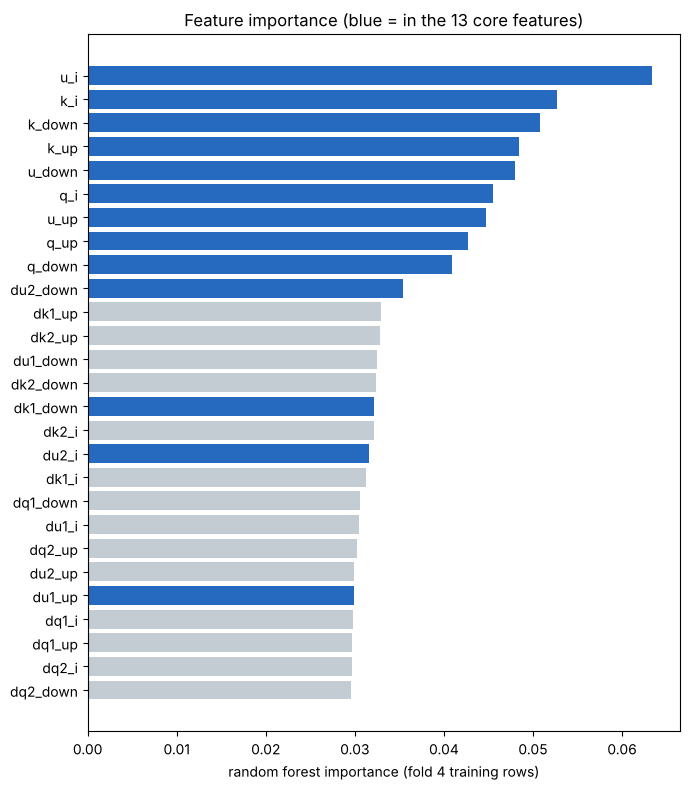

In [13]:
train4, val4 = fold_rows(*val_windows[3])
rows_f = []
for label_name, features in [("all 27 features", ALL_27), ("13 core features", CORE_13)]:
    for balanced in [False, True]:
        pred, score = fit_and_predict("Random forest", balanced, train4, train4["label"].to_numpy(), val4, features)
        r = measures(val4["label"].to_numpy(), pred, score)
        r.update({"features": label_name, "class balancing": "yes" if balanced else "no"})
        rows_f.append(r)
display(pd.DataFrame(rows_f).set_index(["features", "class balancing"]).round(3))

rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=0).fit(train4[ALL_27], train4["label"])
importance = pd.Series(rf.feature_importances_, index=ALL_27).sort_values()
colors = ["#256abf" if f in CORE_13 else "#c3cbd3" for f in importance.index]
plt.figure(figsize=(7, 8))
plt.barh(importance.index, importance.values, color=colors)
plt.xlabel("random forest importance (fold 4 training rows)")
plt.title("Feature importance (blue = in the 13 core features)")
plt.tight_layout()
plt.show()

## 11. Final test on Jul-Dec 2025 (run once)

Locked, as in `data_and_features.ipynb`. When the choice of model is final, set `RUN_FINAL_TEST =
True` and run this cell once. It trains on a sample of all rows before July 2025 and scores the
holdout.

In [14]:
RUN_FINAL_TEST = False
FINAL_MODELS = [("Logistic regression", True), ("Random forest", False)]

if RUN_FINAL_TEST:
    train_all, holdout = fold_rows(test_start, test_end)
    final_rows = []
    for name, balanced in FINAL_MODELS:
        pred, score = fit_and_predict(name, balanced, train_all, train_all["label"].to_numpy(), holdout, ALL_27)
        r = measures(holdout["label"].to_numpy(), pred, score)
        r.update({"model": name, "class balancing": "yes" if balanced else "no"})
        final_rows.append(r)
    display(pd.DataFrame(final_rows).set_index(["model", "class balancing"]).round(3))
else:
    print("Final test not run yet (set RUN_FINAL_TEST = True when all choices are made).")

Final test not run yet (set RUN_FINAL_TEST = True when all choices are made).


## 12. Results in graphs

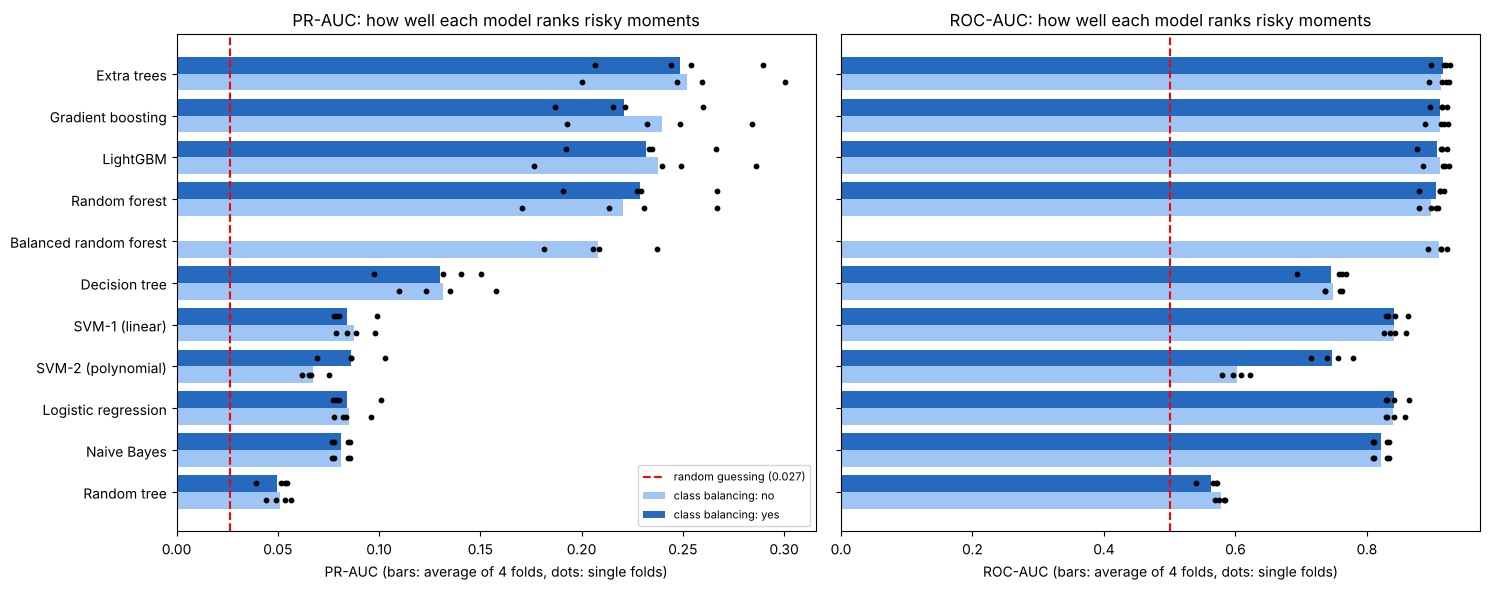

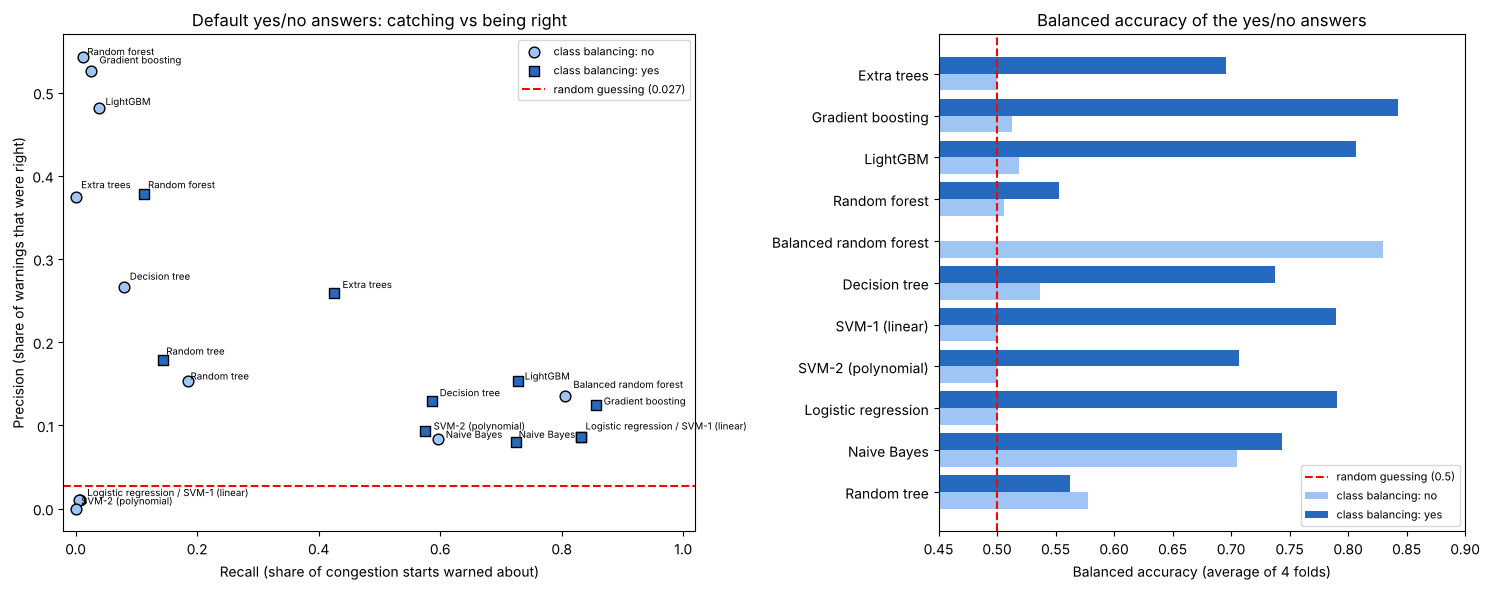

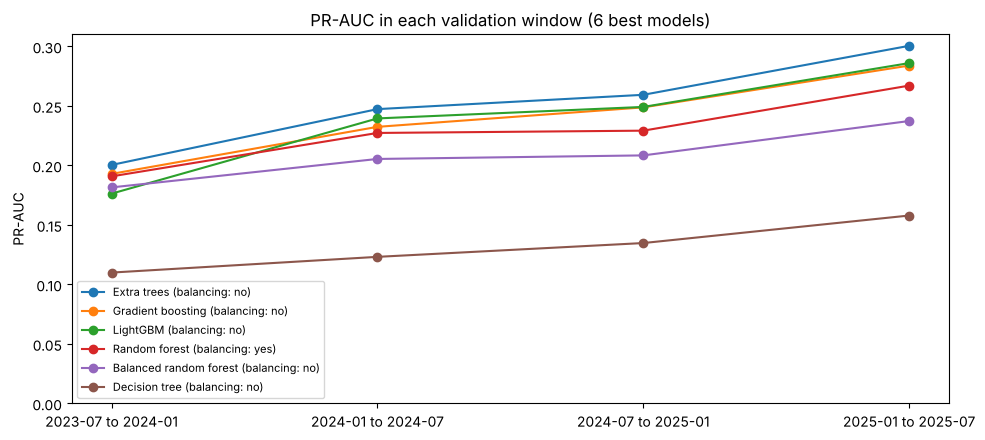

In [15]:
avg = per_fold.groupby(["model", "class balancing"]).mean(numeric_only=True).reset_index()
random_pr = data["label"].mean()                              # PR-AUC of random guessing = share of label-1 rows
order = avg.groupby("model")["PR-AUC"].max().sort_values().index   # best model at the top
colors = {"no": "#9ec5f4", "yes": "#256abf"}
label_of = {"no": "class balancing: no", "yes": "class balancing: yes"}

# ---- 1. ranking: PR-AUC and ROC-AUC, average over the 4 folds (dots = single folds)
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
y_pos = {name: k for k, name in enumerate(order)}
for ax, metric, chance in [(axes[0], "PR-AUC", random_pr), (axes[1], "ROC-AUC", 0.5)]:
    for shift, balancing in [(-0.2, "no"), (0.2, "yes")]:
        part = avg[avg["class balancing"] == balancing]
        ax.barh([y_pos[m] + shift for m in part["model"]], part[metric], height=0.4,
                color=colors[balancing], label=label_of[balancing])
        folds_part = per_fold[per_fold["class balancing"] == balancing]
        ax.scatter(folds_part[metric], [y_pos[m] + shift for m in folds_part["model"]],
                   s=10, color="black", zorder=3)
    ax.axvline(chance, color="red", linestyle="--", label=f"random guessing ({chance:.3f})")
    ax.set_xlabel(f"{metric} (bars: average of 4 folds, dots: single folds)")
    ax.set_title(f"{metric}: how well each model ranks risky moments")
axes[0].set_yticks(range(len(order)))
axes[0].set_yticklabels(order)
axes[0].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

# ---- 2. yes/no warnings at the default cutoff: recall vs precision, and balanced accuracy
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
for balancing, marker in [("no", "o"), ("yes", "s")]:
    part = avg[avg["class balancing"] == balancing]
    ax.scatter(part["TPR (recall)"], part["PPV (precision)"], s=60, marker=marker,
               color=colors[balancing], edgecolor="black", label=label_of[balancing], zorder=3)
    # models whose points (almost) coincide share one label
    spots = part.groupby([part["TPR (recall)"].round(2), part["PPV (precision)"].round(2)])["model"]
    for (x, y_), names in spots:
        ax.annotate(" / ".join(names), (x, y_), fontsize=7, xytext=(4, 3), textcoords="offset points")
ax.axhline(random_pr, color="red", linestyle="--", label=f"random guessing ({random_pr:.3f})")
ax.set_xlabel("Recall (share of congestion starts warned about)")
ax.set_ylabel("Precision (share of warnings that were right)")
ax.set_xlim(-0.02, 1.02)
ax.set_title("Default yes/no answers: catching vs being right")
ax.legend(fontsize=8)

ax = axes[1]
pivot = avg.pivot(index="model", columns="class balancing", values="balanced accuracy").reindex(order)
for shift, balancing in [(-0.2, "no"), (0.2, "yes")]:
    if balancing in pivot:
        ax.barh(np.arange(len(order)) + shift, pivot[balancing], height=0.4,
                color=colors[balancing], label=label_of[balancing])
ax.axvline(0.5, color="red", linestyle="--", label="random guessing (0.5)")
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.set_xlim(0.45, 0.9)
ax.set_xlabel("Balanced accuracy (average of 4 folds)")
ax.set_title("Balanced accuracy of the yes/no answers")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

# ---- 3. stability: PR-AUC in each validation window for the 6 best models
best = (avg.sort_values("PR-AUC", ascending=False).drop_duplicates("model").head(6))
window_names = [f"{a[:7]} to {b[:7]}" for a, b in val_windows]
plt.figure(figsize=(10, 4.5))
for _, r in best.iterrows():
    part = per_fold[(per_fold["model"] == r["model"]) & (per_fold["class balancing"] == r["class balancing"])]
    plt.plot(part["fold"], part["PR-AUC"], marker="o",
             label=f"{r['model']} (balancing: {r['class balancing']})")
plt.xticks(range(1, len(val_windows) + 1), window_names)
plt.ylabel("PR-AUC")
plt.ylim(0, None)
plt.title("PR-AUC in each validation window (6 best models)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()
